In [1]:
# Imports
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import pandas as pd
import re
import pandas as pd
from io import StringIO
import numpy as np
from scipy.stats import gaussian_kde
import json

In [2]:
# Simulations settings
MILP_SOLVERS = {"gurobi", "highs", "cbc", "glpk"}

In [3]:
# Plots settings
SOLVER_ACO = "ACO_v2"
SOLVER_MILP_REFERENCE = "gurobi"
SOLVER_MILP_SCND = "highs"
SOLVER_TWNN = "TWNN"

SOLVER_COLORS = {
    SOLVER_TWNN:       "#1f77b4",  
    SOLVER_ACO:        "#ff7f0e",  
    "milp":            "#2ca02c",  
    SOLVER_MILP_REFERENCE: "#9467bd",  
    SOLVER_MILP_SCND:  "#e377c2",  
    "cbc":             "#fcdf00",  
    "glpk":            "#d62728",  
}

BLUE_PALETTE = [
    "#d0e4f7",  # very light
    "#a8cce8",  # light
    "#7ab4d9",  # medium-light
    "#4682b4",  # steelblue
    "#2e5f8a",  # medium-dark
    "#1a3d61",  # dark
]

SOLVER_LABELS = {
    SOLVER_TWNN: "Twnn",
    SOLVER_ACO:  "Aco",
    SOLVER_MILP_REFERENCE: "Gurobi",
    SOLVER_MILP_SCND:  "HiGHS",
    "cbc":             "CBC",
    "glpk":            "GLPK",
}

SIZE_ORDER = ["small", "medium", "big", "large"]
SIZE_LABELS = {
    "small":  "Pequeño\n(c ≤ 25)",
    "medium": "Mediano\n(25 < c ≤ 50)",
    "big":    "Grande\n(50 < c ≤ 80)",
    "large":  "Muy grande\n(c > 80)",
}

SOLVER_BAR_COLORS = {
    SOLVER_TWNN: ["#1f77b4", "#aec7e8"],  
    SOLVER_ACO:             ["#ff7f0e", "#ffbb78"],  
    "milp":            ["#2ca02c", "#98df8a", "#4db84e"],  
    SOLVER_MILP_REFERENCE:          ["#9467bd", "#c5b0d5"],  
    SOLVER_MILP_SCND:           ["#e377c2", "#f7b6d2"],  
    "cbc":             ["#fcdf00", "#fef4a0"],  
    "glpk":            ["#d62728", "#f5a09b"],  
  }

In [4]:
# Load and process data

with open("../../run_results.sql", "r") as f:
    sql = f.read()

# Extraer el bloque COPY de run_results
match = re.search(
    r"COPY public\.run_results \((.+?)\) FROM stdin;\n(.*?)\\\.",
    sql,
    re.DOTALL,
)

columns = [c.strip() for c in match.group(1).split(",")]
data = match.group(2)

df = pd.read_csv(StringIO(data), sep="\t", names=columns, na_values=["\\N"])

def filter_by_experiment_prefix(df: pd.DataFrame, prefix: str, column: str = "experiment_id") -> pd.DataFrame:
    return df[df[column].str.startswith(prefix)].copy()

def prepare_dataframe(df: pd.DataFrame):
    df = df.copy()

    def extract_size(c):
        if 0 < c <= 25:
            return "small"
        elif 25 < c <= 50:
            return "medium"
        elif 50 < c <= 80:
            return "big"
        else:
            return "large"

    df["size"] = df["c"].apply(extract_size)

    c, v, n = df["c"], df["v"], (df["c"] + 2*df["v"])     
    df['dim'] = c + (2*v)
    
    df["feasible"] = df["feasible"].map({"t": True, "f": False})
    df["valid"] = df["valid"].map({"t": True, "f": False, True: True, False: False})
    df.loc[df["status"] == "error", "status"] = "OOM"
    df["routes"] = df["routes"].apply(lambda x: json.loads(x) if isinstance(x, str) else x)
    return df

df_random = prepare_dataframe(filter_by_experiment_prefix(df=df, prefix="turing8_random"))
df_random_twnn = df_random[df_random['solver'] == SOLVER_TWNN]
df_random_aco = df_random[df_random['solver'] == SOLVER_ACO]
df_random_milp_reference = df_random[df_random['solver'] == SOLVER_MILP_REFERENCE]
df_random_milp_scnd = df_random[df_random['solver'] == SOLVER_MILP_SCND]

df_synthetic = prepare_dataframe(filter_by_experiment_prefix(df=df, prefix="turing8_synthetic"))
df_twnn_syn = df_synthetic[df_synthetic['solver'] == SOLVER_TWNN]
df_milp_reference_syn = df_synthetic[df_synthetic['solver'] == SOLVER_MILP_REFERENCE]
df_milp_scnd_syn = df_synthetic[df_synthetic['solver'] == SOLVER_MILP_SCND]
df_aco_syn = df_synthetic[df_synthetic['solver'] == SOLVER_ACO]

df_twnn = pd.concat([df_twnn_syn, df_random_twnn], ignore_index=True)
df_aco = pd.concat([df_aco_syn, df_random_aco], ignore_index=True)
df_milp_reference = pd.concat([df_milp_reference_syn, df_random_milp_reference], ignore_index=True)
df_milp_scnd = pd.concat([df_milp_scnd_syn, df_random_milp_scnd], ignore_index=True)

In [5]:
dfs = {
    SOLVER_TWNN: df_twnn,
    SOLVER_ACO: df_aco,
    SOLVER_MILP_REFERENCE: df_milp_reference,
    SOLVER_MILP_SCND: df_milp_scnd
}

dfs_reduced = {
    SOLVER_ACO: df_aco,
    SOLVER_MILP_REFERENCE: df_milp_reference,
    SOLVER_MILP_SCND: df_milp_scnd
}

# feasible + valid
gurobi_feasible = df_milp_reference[(df_milp_reference["feasible"] == True) & (df_milp_reference['valid'] == True)].copy()
highs_feasible = df_milp_scnd[((df_milp_scnd["feasible"] == True) & (df_milp_scnd['valid'] == True))].copy()
aco_feasible = df_aco[(df_aco["feasible"] == True) & (df_aco['valid'] == True)].copy()
twnn_feasible = df_twnn[(df_twnn["feasible"] == True) & (df_twnn['valid'] == True)].copy()

solvers_feasibility = {
    SOLVER_TWNN: twnn_feasible,
    SOLVER_ACO: aco_feasible,
    SOLVER_MILP_REFERENCE: gurobi_feasible,
    SOLVER_MILP_SCND: highs_feasible
}

solvers_feasibility_reduced = {
    SOLVER_ACO: aco_feasible,
    SOLVER_MILP_REFERENCE: gurobi_feasible,
    SOLVER_MILP_SCND: highs_feasible
}

for solver, sdf in solvers_feasibility.items():
    print(f"{solver}: {len(sdf)} filas feasible, {sdf[['c','v']].drop_duplicates().shape[0]} pares (c,v)")

TWNN: 18 filas feasible, 18 pares (c,v)
ACO_v2: 26 filas feasible, 26 pares (c,v)
gurobi: 24 filas feasible, 24 pares (c,v)
highs: 20 filas feasible, 20 pares (c,v)


###   5.4 Comparación general

Aclarar que para las instancias tal que status=finished son todas feasibles

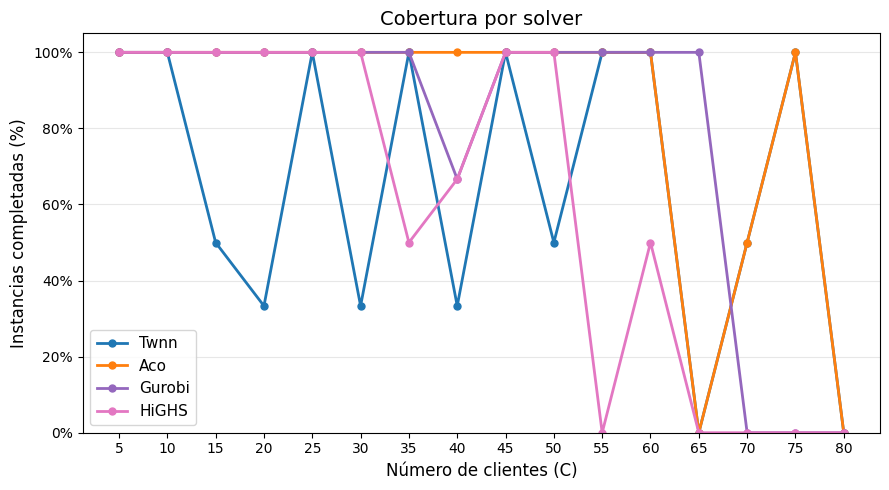

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))

all_c = sorted(df_aco["c"].unique())

for solver, df in dfs.items():
    coverage = (
        df.assign(solvable=df["feasible"] == True)
        .groupby("c")["solvable"]
        .mean() * 100
    )
    ax.plot(
        coverage.index,
        coverage.values,
        marker="o",
        label=SOLVER_LABELS[solver],
        color=SOLVER_COLORS[solver],
        linewidth=2,
        markersize=5,
    )

ax.set_xlabel("Número de clientes (C)", fontsize=12)
ax.set_ylabel("Instancias completadas (%)", fontsize=12)
ax.set_title("Cobertura por solver", fontsize=14)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xticks(all_c)
ax.set_ylim(0, 105)
ax.legend(fontsize=11)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
fig.savefig("figures/cobertura.png", dpi=300, bbox_inches="tight")
plt.show()

/tmp/ipykernel_4253/3900883542.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=violin_df, x="solver", y="ram_usage", ax=axes[0],
/tmp/ipykernel_4253/3900883542.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=violin_df, x="solver", y="cpu_cores", ax=axes[1],


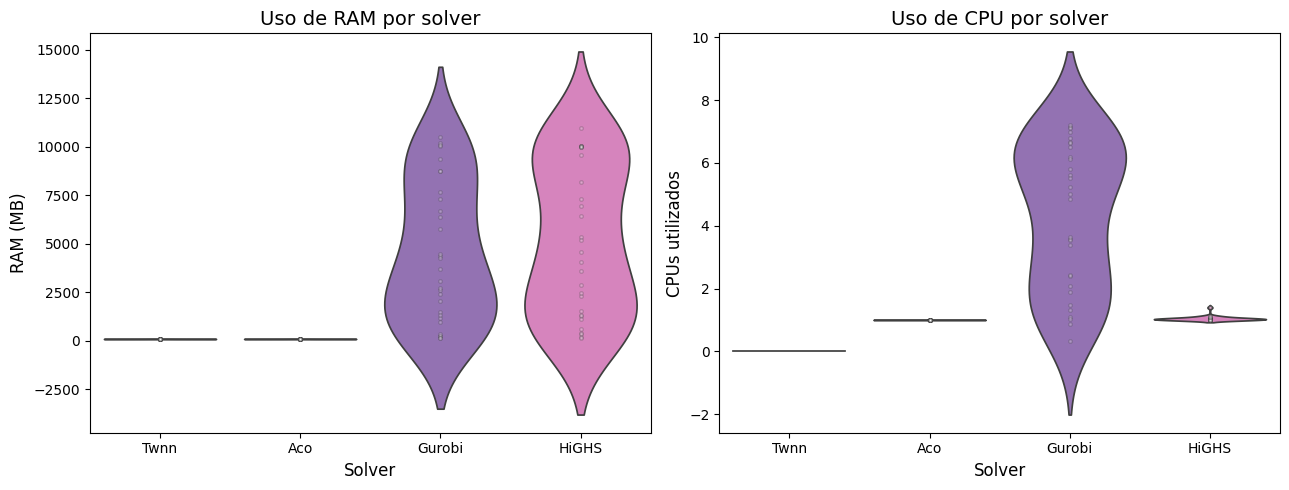

In [7]:
records = []
for solver, df in dfs.items():
    for _, row in df.iterrows():
        records.append({
            "solver":    SOLVER_LABELS[solver],
            "ram_usage": row["ram_usage"],
            "cpu_cores": row["cpu_usage"] / 100 if row["cpu_usage"] is not None else None,
        })

violin_df = pd.DataFrame(records).dropna()
palette = {SOLVER_LABELS[s]: SOLVER_COLORS[s] for s in dfs}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.violinplot(data=violin_df, x="solver", y="ram_usage", ax=axes[0],
                palette=palette, inner="point",
                inner_kws=dict(s=6, alpha=0.25, color="white"))
axes[0].set_title("Uso de RAM por solver", fontsize=14)
axes[0].set_xlabel("Solver", fontsize=12)
axes[0].set_ylabel("RAM (MB)", fontsize=12)

sns.violinplot(data=violin_df, x="solver", y="cpu_cores", ax=axes[1],
                palette=palette, inner="point",
                inner_kws=dict(s=6, alpha=0.25, color="white"))
axes[1].set_title("Uso de CPU por solver", fontsize=14)
axes[1].set_xlabel("Solver", fontsize=12)
axes[1].set_ylabel("CPUs utilizados", fontsize=12)

plt.tight_layout()
plt.show()


/tmp/ipykernel_4253/1207658548.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=violin_df, x="solver", y="ram_usage", ax=ax,


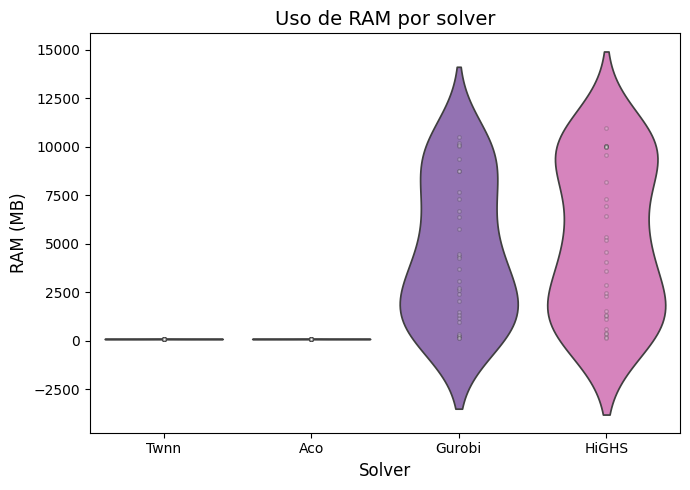

/tmp/ipykernel_4253/1207658548.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=violin_df, x="solver", y="cpu_cores", ax=ax,


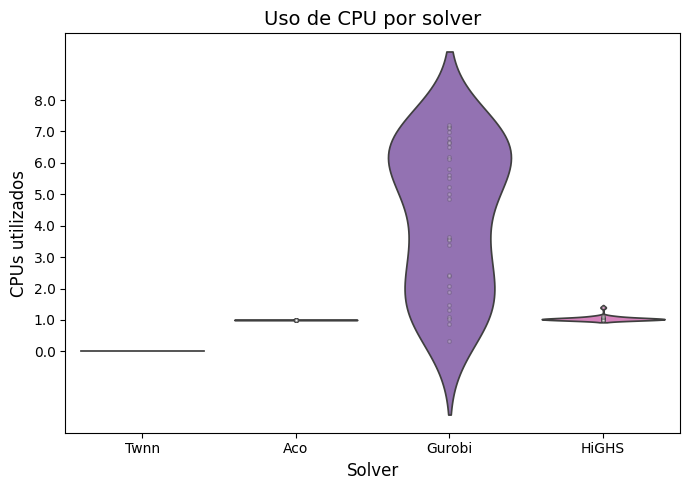

In [8]:
records = []
for solver, df in dfs.items():
    for _, row in df.iterrows():
        records.append({
            "solver":    SOLVER_LABELS[solver],
            "ram_usage": row["ram_usage"],
            "cpu_cores": row["cpu_usage"] / 100 if row["cpu_usage"] is not None else None,
        })

violin_df = pd.DataFrame(records).dropna()
palette = {SOLVER_LABELS[s]: SOLVER_COLORS[s] for s in dfs}

# ── RAM ───────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 5))
sns.violinplot(data=violin_df, x="solver", y="ram_usage", ax=ax,
                palette=palette, inner="point",
                inner_kws=dict(s=6, alpha=0.25, color="white"))
ax.set_title("Uso de RAM por solver", fontsize=14)
ax.set_xlabel("Solver", fontsize=12)
ax.set_ylabel("RAM (MB)", fontsize=12)
plt.tight_layout()
fig.savefig("figures/ram.png", dpi=300, bbox_inches="tight")
plt.show()

# ── CPU ───────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 5))
sns.violinplot(data=violin_df, x="solver", y="cpu_cores", ax=ax,
                palette=palette, inner="point",
                inner_kws=dict(s=6, alpha=0.25, color="white"))
ax.set_title("Uso de CPU por solver", fontsize=14)
ax.set_xlabel("Solver", fontsize=12)
ax.set_ylabel("CPUs utilizados", fontsize=12)
max_cpu = violin_df["cpu_cores"].max()
ticks = np.arange(0, max_cpu + 1, 1)
ax.set_yticks(ticks)
ax.set_yticklabels([f"{t:.1f}" for t in ticks])
plt.tight_layout()
fig.savefig("figures/cpu.png", dpi=300, bbox_inches="tight")
plt.show()


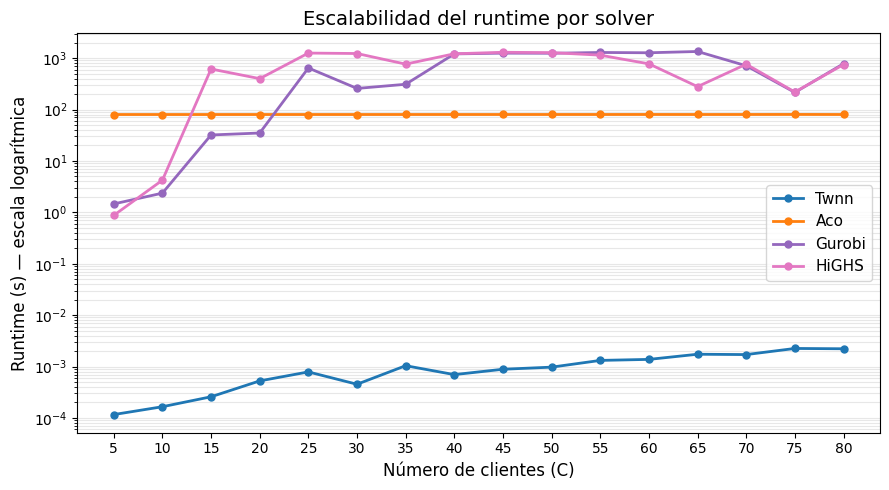

In [9]:
fig, ax = plt.subplots(figsize=(9, 5))

for solver, df in dfs.items():
    if solver == SOLVER_ACO:
        df = df.groupby(["c", "v"])["runtime"].mean().reset_index()
    median_runtime = df.groupby("c")["runtime"].median()
    ax.plot(
        median_runtime.index,
        median_runtime.values,
        marker="o",
        label=SOLVER_LABELS[solver],
        color=SOLVER_COLORS[solver],
        linewidth=2,
        markersize=5,
    )

ax.set_yscale("log")
ax.set_xlabel("Número de clientes (C)", fontsize=12)
ax.set_ylabel("Runtime (s) — escala logarítmica", fontsize=12)
ax.set_title("Escalabilidad del runtime por solver", fontsize=14)
ax.set_xticks(sorted(df_aco["c"].unique()))
ax.legend(fontsize=11)
ax.grid(axis="y", alpha=0.3, which="both")
plt.tight_layout()
plt.show()


/tmp/ipykernel_4253/4200347845.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


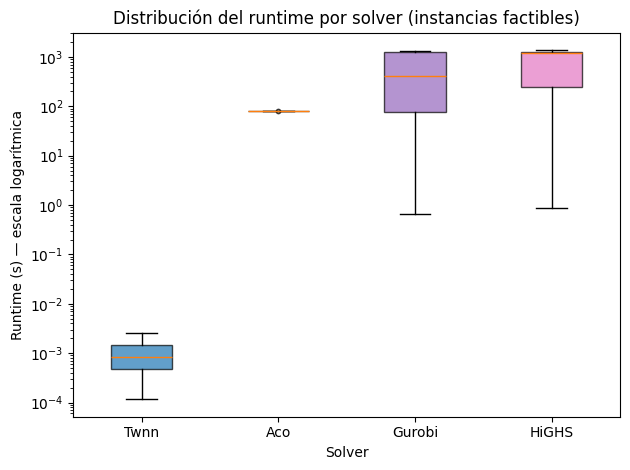

In [10]:
fig, ax = plt.subplots()

data_list = [data["runtime"] for _, data in dfs.items()]
labels = [SOLVER_LABELS[solver] for solver, _ in dfs.items()]
colors = [SOLVER_COLORS[solver] for solver, _ in dfs.items()]

bp = ax.boxplot(
    data_list,
    labels=labels,
    patch_artist=True,
    flierprops=dict(marker="o", markersize=3, alpha=0.4),
)

for patch, color in zip(bp["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

ax.set_yscale("log")
ax.set_title("Distribución del runtime por solver (instancias factibles)")
ax.set_xlabel("Solver")
ax.set_ylabel("Runtime (s) — escala logarítmica")

plt.tight_layout()
plt.show()

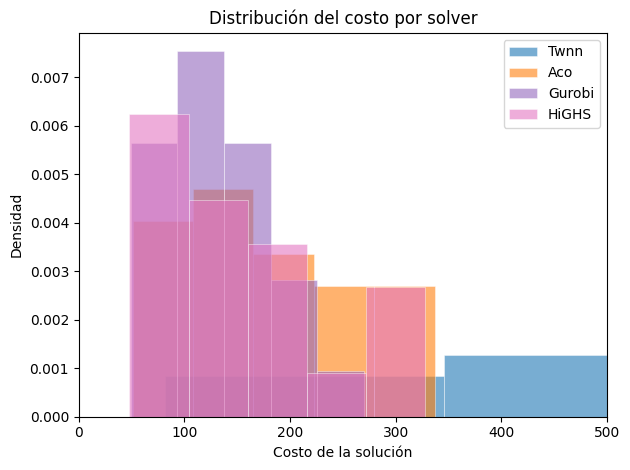

In [11]:
fig, ax = plt.subplots()

for solver, data in solvers_feasibility.items():
    ax.hist(
        data["cost"],
        bins=5,
        color=SOLVER_COLORS[solver],
        edgecolor="white",
        linewidth=0.5,
        alpha=0.6,
        density=True,
        label=SOLVER_LABELS[solver],
    )

ax.set_title("Distribución del costo por solver")
ax.set_xlabel("Costo de la solución")
ax.set_ylabel("Densidad")
ax.legend()
ax.set_xlim(0, 500)

plt.tight_layout()
plt.show()

Es una versión suavizada del histograma. En lugar de apilar barras por bins, coloca una campana gaussiana sobre cada punto y las suma. El resultado es una curva continua que estima la distribución del costo. La altura representa densidad de probabilidad — picos altos = esa zona de costos es muy frecuente.

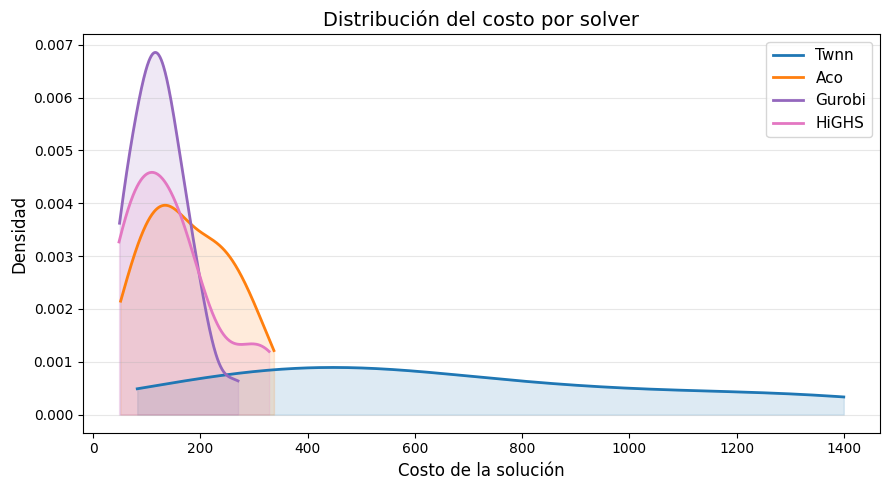

In [12]:
fig, ax = plt.subplots(figsize=(9, 5))

for solver, data in solvers_feasibility.items():
    costs = data["cost"].values
    if len(costs) < 2:
        continue
    kde = gaussian_kde(costs)
    x = np.linspace(costs.min(), costs.max(), 300)
    ax.plot(x, kde(x), label=SOLVER_LABELS[solver], color=SOLVER_COLORS[solver], linewidth=2)
    ax.fill_between(x, kde(x), alpha=0.15, color=SOLVER_COLORS[solver])

ax.set_title("Distribución del costo por solver", fontsize=14)
ax.set_xlabel("Costo de la solución", fontsize=12)
ax.set_ylabel("Densidad", fontsize=12)
ax.legend(fontsize=11)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [13]:
# Comparación justa de costos: solo instancias donde TWNN encontró solución factible
# TWNN es el solver más limitado → filtramos todos los demás a sus mismas instancias
twnn_feasible_ids = set(twnn_feasible["instance_id"])

solvers_feasibility_on_twnn = {
    solver: sdf[sdf["instance_id"].isin(twnn_feasible_ids)].copy()
    for solver, sdf in solvers_feasibility.items()
}

for solver, sdf in solvers_feasibility_on_twnn.items():
    print(f"{solver}: {len(sdf)} filas en instancias TWNN-feasible")

TWNN: 18 filas en instancias TWNN-feasible
ACO_v2: 18 filas en instancias TWNN-feasible
gurobi: 16 filas en instancias TWNN-feasible
highs: 13 filas en instancias TWNN-feasible


/tmp/ipykernel_4253/3730523701.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


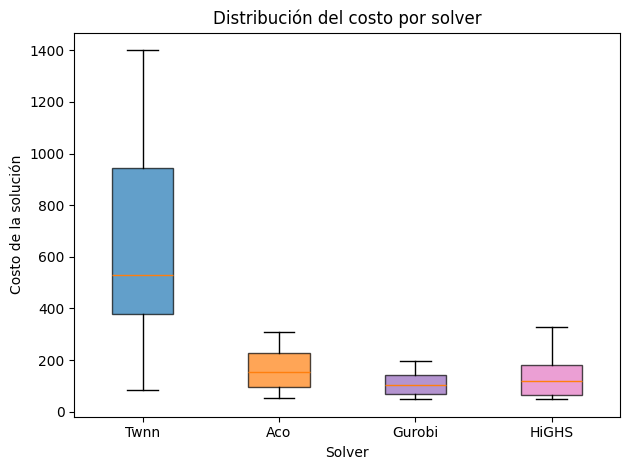

Twnn: media=662.8, mediana=528.0
Aco: media=163.7, mediana=155.5
Gurobi: media=109.4, mediana=104.5
HiGHS: media=141.1, mediana=118.0


In [14]:
fig, ax = plt.subplots()

data_list = [data["cost"] for _, data in solvers_feasibility_on_twnn.items()]

bp = ax.boxplot(
    data_list,
    labels=[SOLVER_LABELS[solver] for solver, _ in dfs.items()],
    patch_artist=True,
    flierprops=dict(marker="o", markersize=3, alpha=0.4),
)

for patch, color in zip(bp["boxes"], [SOLVER_COLORS[solver] for solver, _ in dfs.items()]):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

ax.set_title("Distribución del costo por solver")
ax.set_xlabel("Solver")
ax.set_ylabel("Costo de la solución")

plt.tight_layout()
fig.savefig("figures/distribucion_costos.png", dpi=300, bbox_inches="tight")
plt.show()

for solver, data in solvers_feasibility_on_twnn.items():
    print(f"{SOLVER_LABELS[solver]}: media={data['cost'].mean():.1f}, mediana={data['cost'].median():.1f}")

Concluimos que TWNN no esta en el mismo rango que el resto y la comparacion siguie sin el.
De igual forma hay que filtrar las instacias en comun para los 3 solvers restantes

In [15]:
# Instancias donde ACO, HiGHS y Gurobi fueron todos feasible (sin TWNN)
aco_feasible_ids    = set(aco_feasible["instance_id"])
highs_feasible_ids  = set(highs_feasible["instance_id"])
gurobi_feasible_ids = set(gurobi_feasible["instance_id"])

common_ids_reduced = aco_feasible_ids & highs_feasible_ids & gurobi_feasible_ids

solvers_feasibility_reduced_common = {
    solver: sdf[sdf["instance_id"].isin(common_ids_reduced)].copy()
    for solver, sdf in solvers_feasibility_reduced.items()
}

for solver, sdf in solvers_feasibility_reduced_common.items():
    print(f"{solver}: {len(sdf)} filas en instancias comunes (ACO ∩ HiGHS ∩ Gurobi)")

ACO_v2: 20 filas en instancias comunes (ACO ∩ HiGHS ∩ Gurobi)
gurobi: 20 filas en instancias comunes (ACO ∩ HiGHS ∩ Gurobi)
highs: 20 filas en instancias comunes (ACO ∩ HiGHS ∩ Gurobi)


/tmp/ipykernel_4253/3246148321.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


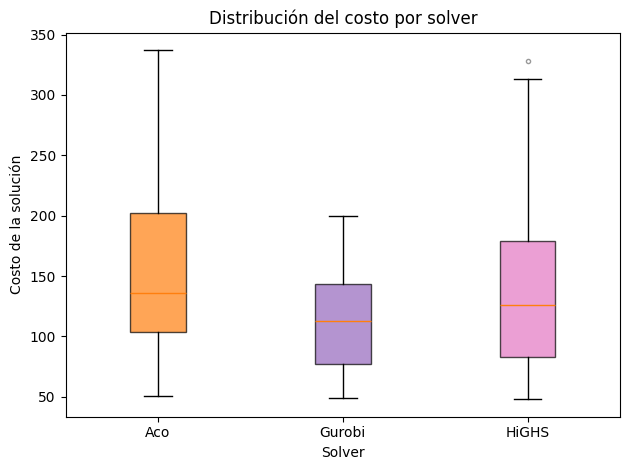

Aco: media=158.2, mediana=136.0, std=81.6
Gurobi: media=114.7, mediana=112.5, std=47.0
HiGHS: media=146.7, mediana=126.0, std=86.3


In [16]:
fig, ax = plt.subplots()

data_list = [data["cost"] for _, data in solvers_feasibility_reduced_common.items()]

bp = ax.boxplot(
    data_list,
    labels=[SOLVER_LABELS[solver] for solver, _ in solvers_feasibility_reduced_common.items()],
    patch_artist=True,
    flierprops=dict(marker="o", markersize=3, alpha=0.4),
)

for patch, color in zip(bp["boxes"], [SOLVER_COLORS[solver] for solver, _ in solvers_feasibility_reduced_common.items()]):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

ax.set_title("Distribución del costo por solver")
ax.set_xlabel("Solver")
ax.set_ylabel("Costo de la solución")

plt.tight_layout()
fig.savefig("figures/distribucion_costos2.png", dpi=300, bbox_inches="tight")
plt.show()

for solver, data in solvers_feasibility_reduced_common.items():
    print(f"{SOLVER_LABELS[solver]}: media={data['cost'].mean():.1f}, mediana={data['cost'].median():.1f}, std={data['cost'].std():.1f}")

/tmp/ipykernel_4253/1540886612.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


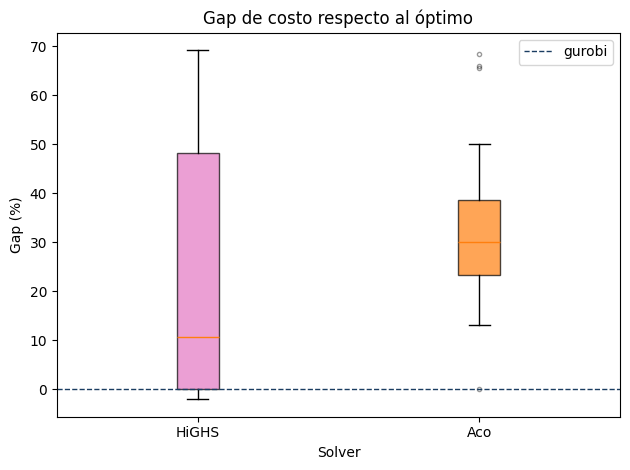

HiGHS: media=20.8%, std=26.5%, mediana=10.7%
Aco: media=33.1%, std=18.2%, mediana=30.0%


In [17]:
gurobi_ok   = solvers_feasibility_reduced_common[SOLVER_MILP_REFERENCE][["c", "v", "cost"]].rename(columns={"cost": "gurobi_cost"})
aco_mean  = solvers_feasibility_reduced_common[SOLVER_ACO][["c", "v", "cost"]].rename(columns={"cost": "cost_aco"})
highs_ok  = solvers_feasibility_reduced_common[SOLVER_MILP_SCND][["c", "v", "cost"]].rename(columns={"cost": "cost_highs"})

gap_df = gurobi_ok.merge(aco_mean, on=["c", "v"]).merge(highs_ok, on=["c", "v"])
gap_df["gap_aco"]   = (gap_df["cost_aco"]   - gap_df["gurobi_cost"]) / gap_df["gurobi_cost"] * 100
gap_df["gap_highs"] = (gap_df["cost_highs"] - gap_df["gurobi_cost"]) / gap_df["gurobi_cost"] * 100

solvers_gap = [
    ("gap_highs", SOLVER_MILP_SCND),
    ("gap_aco",   SOLVER_ACO),
]

fig, ax = plt.subplots()

bp = ax.boxplot(
    [gap_df[col] for col, _ in solvers_gap],
    labels=[SOLVER_LABELS[s] for _, s in solvers_gap],
    patch_artist=True,
    flierprops=dict(marker="o", markersize=3, alpha=0.4),
)

for patch, (_, solver) in zip(bp["boxes"], solvers_gap):
    patch.set_facecolor(SOLVER_COLORS[solver])
    patch.set_alpha(0.7)

ax.axhline(0, color="#1a3d61", linestyle="--", linewidth=1, label=SOLVER_MILP_REFERENCE)
ax.set_title("Gap de costo respecto al óptimo")
ax.set_xlabel("Solver")
ax.set_ylabel("Gap (%)")
ax.legend()

plt.tight_layout()
fig.savefig("figures/gap.png", dpi=300, bbox_inches="tight")
plt.show()

for col, solver in solvers_gap:
    print(f"{SOLVER_LABELS[solver]}: media={gap_df[col].mean():.1f}%, std={gap_df[col].std():.1f}%, mediana={gap_df[col].median():.1f}%")

In [18]:
summary = pd.DataFrame({
    SOLVER_LABELS[solver]: {
        "Mínimo":  gap_df[col].min(),
        "Máximo":  gap_df[col].max(),
        "Promedio": gap_df[col].mean(),
        "Std": gap_df[col].std(),
    }
    for col, solver in solvers_gap
}).round(1)

print(summary.to_string())
# print(summary.to_latex(float_format="%.1f"))

          HiGHS   Aco
Mínimo     -2.0   0.0
Máximo     69.2  68.5
Promedio   20.8  33.1
Std        26.5  18.2


Gap en las instancias en las que gurobi hizo timeout, el objetivo es comparar una solucion no optima de milp vs la solucion de aco (tener en cuenta la diferencia de runtime)

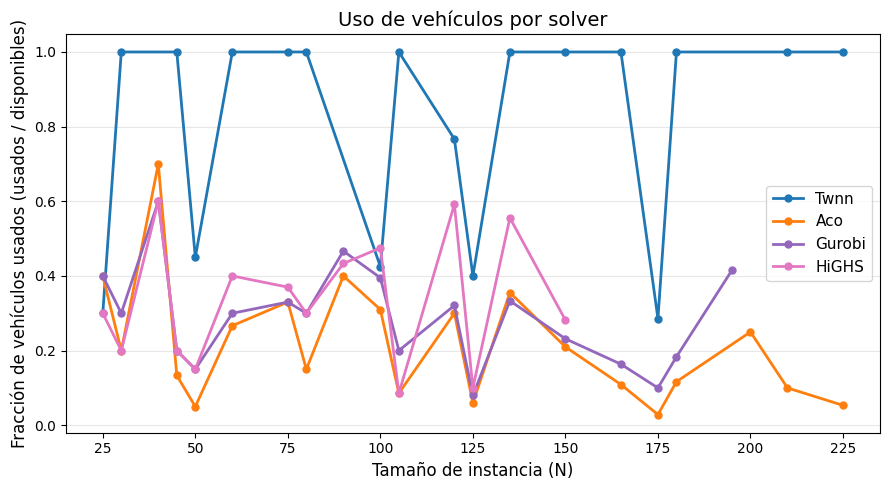

In [19]:
def n_vehicles(routes):
    if routes is None:
        return None
    return len(routes)

fig, ax = plt.subplots(figsize=(9, 5))

for solver, df in solvers_feasibility.items():
    df["n_vehicles"] = df["routes"].apply(n_vehicles)
    df["veh_ratio"]  = df["n_vehicles"] / df["v"]

    scatter = df.groupby("dim")["veh_ratio"].median()
    ax.plot(
        scatter.index,
        scatter.values,
        marker="o",
        label=SOLVER_LABELS[solver],
        color=SOLVER_COLORS[solver],
        linewidth=2,
        markersize=5,
    )

ax.set_xlabel("Tamaño de instancia (N)", fontsize=12)
ax.set_ylabel("Fracción de vehículos usados (usados / disponibles)", fontsize=12)
ax.set_title("Uso de vehículos por solver", fontsize=14)
ax.legend(fontsize=11)
ax.grid(axis="y", alpha=0.3)
fig.savefig("figures/uso_vehiculos.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

a medida que fui introduciendo nuevos modulos a aco, se fue aproximando al ratio de milp. antes estaba mas cerca del ratio de twnn porque comenzaban igual.

In [20]:
import networkx as nx
import json

def build_graph(routes):
    if isinstance(routes, str):
        routes = json.loads(routes)
    G = nx.DiGraph()
    for route in routes.values():
        for i in range(len(route) - 1):
            G.add_edge(route[i], route[i+1])
    return G, routes

def plot_routes_comparison(instance_row_per_solver: dict, title_prefix=""):
    """instance_row_per_solver: {solver_name: row_df_con_routes}"""

    # Layout compartido basado en la union de todos los grafos
    all_nodes = set()
    for row in instance_row_per_solver.values():
        routes = json.loads(row["routes"]) if isinstance(row["routes"], str) else row["routes"]
        for route in routes.values():
            all_nodes.update(route)

    G_union = nx.Graph()
    G_union.add_nodes_from(all_nodes)
    pos = nx.spring_layout(G_union, seed=42)

    n_solvers = len(instance_row_per_solver)
    # fig, axes = plt.subplots(1, n_solvers, figsize=(7 * n_solvers, 6))
    # if n_solvers == 1:
    #     axes = [axes]
    fig, axes = plt.subplots(2, 2, figsize=(14, 12))
    axes = axes.flatten()

    colors = plt.cm.tab10.colors

    for ax, (solver, row) in zip(axes, instance_row_per_solver.items()):
        routes = json.loads(row["routes"]) if isinstance(row["routes"], str) else row["routes"]

        depot_start = set()
        depot_end   = set()
        customers   = set()
        for route in routes.values():
            depot_start.add(route[0])
            depot_end.add(route[-1])
            customers.update(route[1:-1])

        G, _ = build_graph(routes)

        # Aristas coloreadas por ruta
        for i, route in enumerate(routes.values()):
            edges = [(route[j], route[j+1]) for j in range(len(route) - 1)]
            nx.draw_networkx_edges(G, pos, edgelist=edges,
                                    edge_color=[colors[i % len(colors)]],
                                    arrows=True, ax=ax, width=1.8,
                                    arrowsize=12, connectionstyle="arc3,rad=0.1")

        # Nodos
        nx.draw_networkx_nodes(G, pos, nodelist=list(depot_start),
                                node_shape="s", node_color="black", node_size=250, ax=ax)
        nx.draw_networkx_nodes(G, pos, nodelist=list(depot_end),
                                node_shape="^", node_color="black", node_size=250, ax=ax)
        nx.draw_networkx_nodes(G, pos, nodelist=list(customers),
                                node_shape="o", node_color="steelblue", node_size=120, ax=ax)
        nx.draw_networkx_labels(G, pos, ax=ax, font_size=6, font_color="white")

        ax.set_title(f"{title_prefix} — {SOLVER_LABELS.get(solver, solver)}\n"
                    f"{len(routes)} vehículos usados", fontsize=12)
        
        ax.set_title(f"{title_prefix} — {SOLVER_LABELS.get(solver, solver)}\n"
                    f"{len(routes)} vehículos usados | costo: {row['cost']:.1f}", fontsize=12)
        ax.axis("off")

    # Leyenda
    depot_patch  = plt.Line2D([0], [0], marker="s", color="w", markerfacecolor="black",
                                markersize=10, label="Depot")
    return_patch = plt.Line2D([0], [0], marker="^", color="w", markerfacecolor="black",
                                markersize=10, label="Return")
    customer_patch = plt.Line2D([0], [0], marker="o", color="w", markerfacecolor="steelblue",
                                markersize=8, label="Cliente")
    fig.legend(handles=[depot_patch, return_patch, customer_patch], loc="lower center",
                ncol=3, fontsize=11, bbox_to_anchor=(0.5, -0.02))


    plt.tight_layout()
    fig.savefig("figures/asignaciones.png", dpi=300, bbox_inches="tight")
    plt.show()


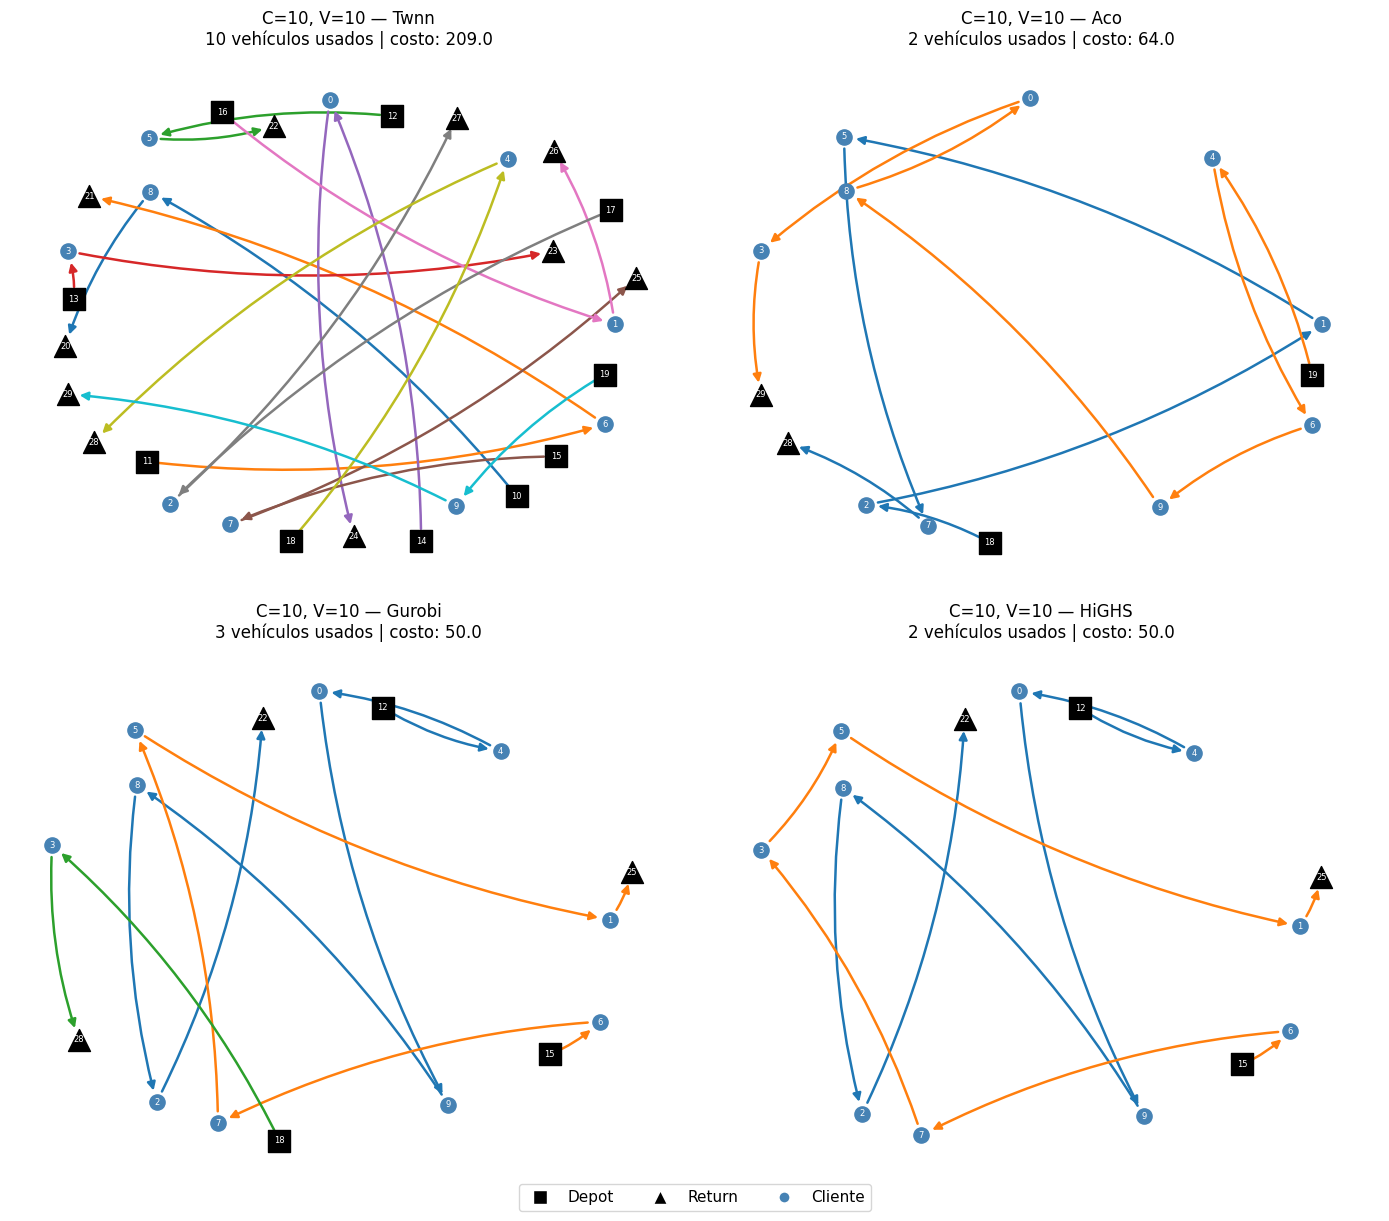

In [21]:
C, V = 10, 10  # instancia a visualizar

rows = {}
for solver, df in solvers_feasibility.items():
    #if solver in [SOLVER_TWNN, SOLVER_MILP_SCND]:
    #    continue
    match = df[(df["c"] == C) & (df["v"] == V)]
    if not match.empty:
        rows[solver] = match.iloc[0]

plot_routes_comparison(rows, title_prefix=f"C={C}, V={V}")


In [22]:
idx = gap_df["gap_aco"].idxmax()
print(gap_df.loc[idx, ["c", "v", "gap_aco"]])

c          50.0
v          25.0
gap_aco    68.5
Name: 19, dtype: float64


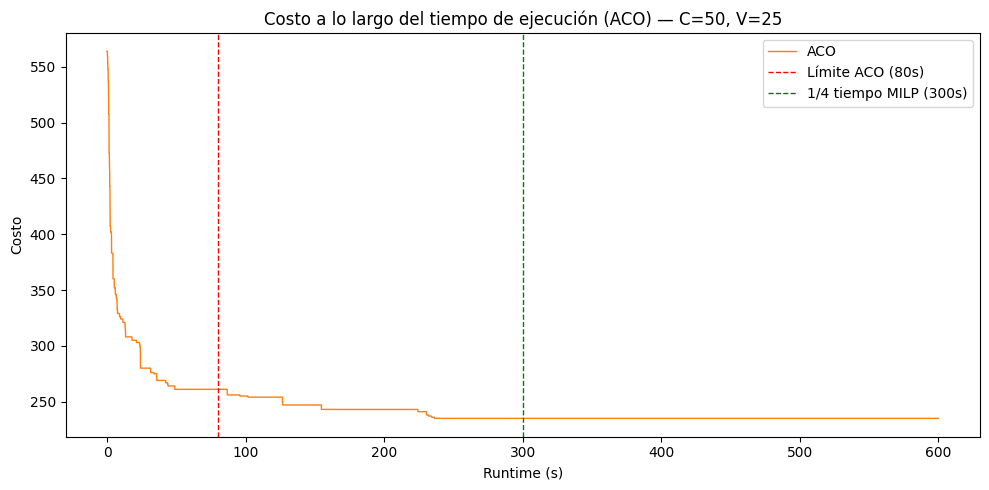

In [23]:
import re
import ast
import matplotlib.pyplot as plt

with open("ACO_600S.txt", "r") as f:
    content = f.read()

# Replace np.int64(x) with plain int so ast.literal_eval can handle it
content = re.sub(r"np\.int64\((\d+)\)", r"\1", content)
content = re.sub(r"\binf\b", "1e999", content)

runs = ast.literal_eval(content)
runs = ast.literal_eval(content)

fig, ax = plt.subplots(figsize=(10, 5))

for run in runs:
    times = []
    costs = []
    for t, c in run:
        if c == float("inf"):
            continue  # skip initial inf point
        times.append(t)
        costs.append(c)
    ax.plot(times, costs, alpha=1, linewidth=1, color=SOLVER_COLORS[SOLVER_ACO], label='ACO')

ax.axvline(x=80, color='red', linestyle='--', linewidth=1, label='Límite ACO (80s)')
ax.axvline(x=300, color='green', linestyle='--', linewidth=1, label='1/4 tiempo MILP (300s)')
ax.legend()

ax.set_xlabel("Runtime (s)")
ax.set_ylabel("Costo")
ax.set_title("Costo a lo largo del tiempo de ejecución (ACO) — C=50, V=25")
plt.tight_layout()
fig.savefig("figures/aco_cost_over_time.png", dpi=300, bbox_inches="tight")
plt.show()

In [24]:
import numpy as np

# Flatten all runs into arrays
all_times = []
all_costs = []
for run in runs:
    for t, c in run:
        if c != float("inf"):
            all_times.append(t)
            all_costs.append(c)

all_times = np.array(all_times)
all_costs = np.array(all_costs)

# Find closest point to 80s and 300s
idx_80 = np.argmin(np.abs(all_times - 80))
idx_300 = np.argmin(np.abs(all_times - 300))

costo_80 = all_costs[idx_80]
costo_300 = all_costs[idx_300]

ganancia = ((costo_80 - costo_300) / costo_80) * 100

print(f"Costo en ~80s:  {costo_80}")
print(f"Costo en ~300s: {costo_300}")
print(f"Ganancia: {ganancia:.2f}%")

optimo = 200
gap_80 = ((costo_80 - optimo) / optimo) * 100
gap_300 = ((costo_300 - optimo) / optimo) * 100

print(f"Gap con Gurobi en ~80s:  {gap_80:.2f}%")
print(f"Gap con Gurobi en ~300s: {gap_300:.2f}%")
#ganancia (%) = ((valor_inicial - valor_final) / valor_inicial) * 100

Costo en ~80s:  261
Costo en ~300s: 235
Ganancia: 9.96%
Gap con Gurobi en ~80s:  30.50%
Gap con Gurobi en ~300s: 17.50%


este grafico muestra lo que pasaria si corrieramos aco durante la mitad de tiempo que milp (600s == 10min) para el caso del mayor gap entre aco y gurobi, c=50 y v=25. Podemos notar que bastaria con correr simplemente 5m minutos envez de los diez para llegar a la meseta, que no vamos a poder seguir bajando el costo porque el problema deja de ser la exploracion y pasa a ser problema estructural.
Con estos 520s de mas que le damos a aco, logra mejorar la solucion en un 9,96%, y quedando a tan solo un 17,5% de gap de la solucion de gurobi

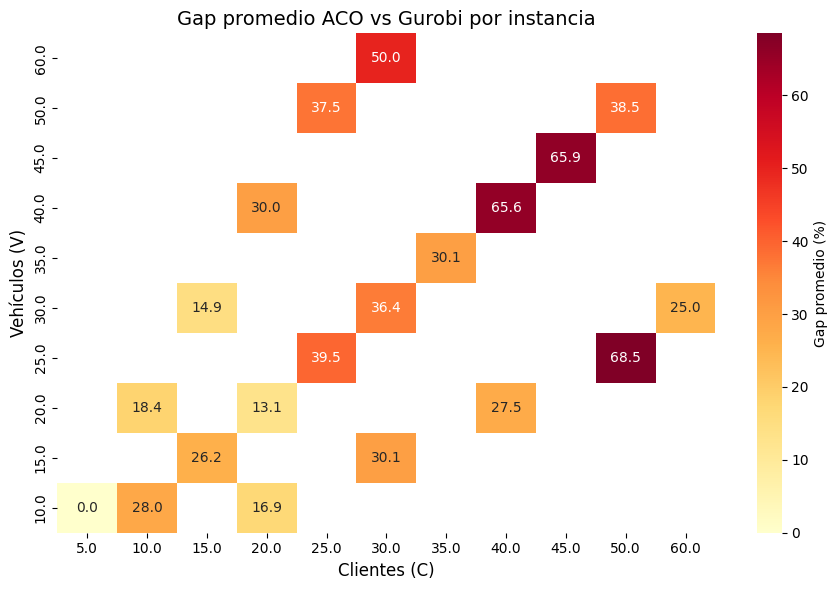

In [25]:
gap_df['c_bin'] = (gap_df['c'] // 5) * 5
gap_df['v_bin'] = (gap_df['v'] // 5) * 5

heatmap_data = gap_df.pivot_table(index='v_bin', columns='c_bin', values='gap_aco', aggfunc='mean')

fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='.1f',
    cmap='YlOrRd',
    ax=ax,
    cbar_kws={'label': 'Gap promedio (%)'},
)
ax.set_xlabel('Clientes (C)', fontsize=12)
ax.set_ylabel('Vehículos (V)', fontsize=12)
ax.invert_yaxis()
ax.set_title('Gap promedio ACO vs Gurobi por instancia', fontsize=14)
plt.tight_layout()
fig.savefig("figures/gap_heatmap_aco_gurobi.png", dpi=300, bbox_inches="tight")
plt.show()


In [26]:
for solver, df in dfs.items():
    out = df.copy()
    out['generator'] = out['experiment_id'].str.extract(r'turing8_(\w+)_')
    out = out[['c', 'v', 'generator', 'cost', 'runtime', 'cpu_usage', 'ram_usage']]
    out.sort_values('c').to_csv(f"{SOLVER_LABELS[solver]}.csv", index=False)
